# Bass model analysis of Posha
Roman Ghukasyan | Marketing Analytics | October 19, 2026

Running all cells extracts the CSV from the saved EIA HTML, fits the model, creates the forecast and charts, and builds the PDF from report/report_source.md. The report Markdown and reference list are written source files. No precomputed CSV or PDF is needed.

## 1. Chosen innovation
I chose Posha from TIME's Best Inventions of 2025. It is a kitchen robot that cooks one-pot meals. The user prepares and loads the ingredients, then Posha adds them, stirs and uses a camera to adjust the cooking [R1, R2]. I found it interesting because it could help people who want home-cooked food but do not have much time to stand next to the stove.

## 2. Look-alike innovation: the countertop microwave
I chose the microwave because both products bring a different way of preparing food into the home. Both take kitchen space, cost money and help reduce the time or attention needed for cooking. For either product, seeing another household use it could make the benefits easier to understand. BLS reports that the countertop microwave was introduced in 1967 [R5].

The technologies are different. A microwave heats food, while Posha automates several cooking steps. Also, the microwave data covers a whole category and Posha is one brand. So I use microwave diffusion as a starting comparison and estimate a much smaller market for Posha. I do not expect the two products to reach the same level of ownership.

## 3. Historical data
I use U.S. microwave ownership from EIA Table 2.6 [R3]. There are 12 usable observations from 1978 to 2009. I leave the missing 1979 entry out of estimation and keep the actual survey years, without filling the gaps. The original table and extracted CSV are in data/.

Ownership is a proxy for cumulative adoption, not a direct count of first purchases. I fit ownership shares so growth in the number of households does not get mixed with diffusion. To express historical M in household units, I use the fixed 1978 base of 77 million households [R3]. These are standardized household equivalents, not actual unique buyers. The small fall in ownership from 1993 to 1997 stays in the data because these are rounded survey estimates.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from helper_functions import bass_cumulative, bass_from_seed, fit_bass, rmse
from extract_data import extract_microwave_data

ROOT = Path.cwd()
(ROOT / 'img').mkdir(exist_ok=True)
raw = extract_microwave_data()
print('Created data/microwave_us_raw.csv from the saved EIA HTML.')
print(raw[['year', 'households_millions', 'microwave_ownership_pct']].to_string(index=False))

Created data/microwave_us_raw.csv from the saved EIA HTML.
 year  households_millions  microwave_ownership_pct
 1978                 77.0                      8.0
 1979                 78.0                      NaN
 1980                 82.0                     14.0
 1981                 83.0                     17.0
 1982                 84.0                     21.0
 1984                 86.0                     34.0
 1987                 91.0                     61.0
 1990                 94.0                     79.0
 1993                 97.0                     84.0
 1997                101.0                     83.0
 2001                107.0                     86.0
 2005                111.0                     88.0
 2009                114.0                     96.0


## 4. Estimate p, q and M
I use the cumulative Bass model [R6]:

N(t) = M * (1 - exp(-(p+q)*t)) / (1 + (q/p)*exp(-(p+q)*t))

Here p describes external influence, q describes imitation, M is market potential and N(t) is cumulative adoption. Time is measured in years from 1967. I estimate p, q and the ownership ceiling together with nonlinear least squares, giving each survey the same weight. The ceiling is restricted to between 50% and 100%. The helper tries several starting values, and none of the fitted parameters is at a bound.

In [2]:
data = raw.dropna(subset=['microwave_ownership_pct']).copy()
years = data['year'].to_numpy()
shares = data['microwave_ownership_pct'].to_numpy() / 100
p, q, ceiling = fit_bass(years, shares, origin=1967)
fitted = bass_cumulative(years - 1967, p, q, ceiling)
reference_households = raw.loc[raw.year == 1978, 'households_millions'].iloc[0] * 1_000_000
historical_M = reference_households * ceiling
r2 = 1 - np.sum((shares - fitted)**2) / np.sum((shares - shares.mean())**2)
error_pp = 100 * rmse(shares, fitted)
print(f'p = {p:.8f} per year')
print(f'q = {q:.8f} per year')
print(f'Historical M = {historical_M / 1e6:.2f} million household equivalents')
print(f'Ownership ceiling = {100 * ceiling:.2f}%')
print(f'R-squared = {r2:.4f}')
print(f'RMSE = {error_pp:.2f} percentage points')

p = 0.00050491 per year
q = 0.36524560 per year
Historical M = 68.52 million household equivalents
Ownership ceiling = 88.98%
R-squared = 0.9921
RMSE = 2.91 percentage points


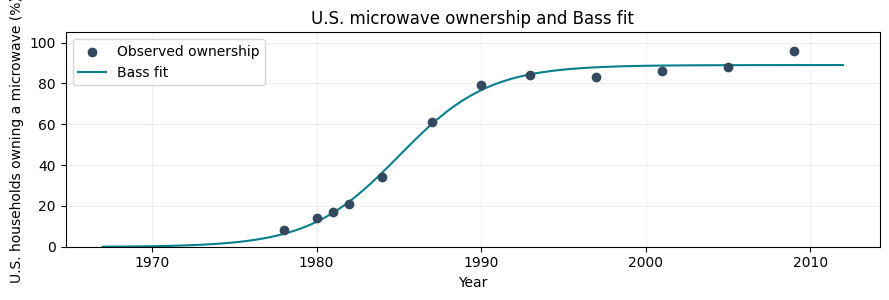

In [3]:
smooth_years = np.linspace(1967, 2012, 300)
fig, ax = plt.subplots(figsize=(9, 3.1))
ax.scatter(years, 100 * shares, color='#34495e', label='Observed ownership', zorder=3)
ax.plot(smooth_years, 100 * bass_cumulative(smooth_years - 1967, p, q, ceiling),
        color='#087f8c', label='Bass fit')
ax.set(xlabel='Year', ylabel='U.S. households owning a microwave (%)',
       title='U.S. microwave ownership and Bass fit', ylim=(0, 105))
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ROOT / 'img/microwave_fit.png', dpi=180)
plt.show()

The fitted model follows the main rise in ownership. R-squared is 0.9921 and RMSE is 2.91 percentage points. Still, the estimated ceiling is about 89%, while the last observed value is 96%. So the fit is useful for the comparison but it misses some later growth. These are fit measures, not evidence that the Posha forecast is accurate.

## 5. Predict Posha's diffusion
I use the estimated microwave p and q as an assumption for Posha. These rates are not fitted to Posha sales. I estimate a separate market because a premium robot from one company is different from the whole microwave market.

Census reports 132,737,146 U.S. households in 2024 [R4]. Posha lists a regular price of $1,750 [R2], so I treat it as a premium purchase. Using Fermi logic, I assume 20% of households could afford it, have suitable space and want cooking help. I then assume 2.5% of this group eventually chooses Posha. Both percentages are my assumptions, not survey results.

M = 132,737,146 * 0.20 * 0.025 = 663,685.73 households

This is about 664,000 households, or 0.5% of all U.S. households. The manufacturer's page says Posha is in 1,000+ homes [R2]. I use exactly 1,000 as a planning starting value at the beginning of 2027. This is not an observed end-of-2026 total. The forecast starts from these households rather than restarting adoption from zero. I keep the household base and market potential fixed.

In [4]:
households = 132_737_146  # Census 2024, R4
eligible_share = 0.20  # Fermi assumption
posha_take_up = 0.025  # Fermi assumption
M_posha = households * eligible_share * posha_take_up
initial_households = 1_000  # Planning assumption based on R2
print(f'Posha market potential = {M_posha:,.2f} households')
print(f'Share of all U.S. households = {100 * M_posha / households:.1f}%')

Posha market potential = 663,685.73 households
Share of all U.S. households = 0.5%


## 6. Scope: United States
I chose the U.S. because Posha currently ships there [R2] and the microwave data also covers U.S. households [R3]. This keeps the same country for both products. I count households because several people can share one appliance. One household is counted once, and replacement purchases are not additional adopters.

## 7. Adopters by year
The forecast covers the end of each year from 2027 to 2046. Cumulative adoption includes the starting 1,000 households. New adopters in a year are N(t) - N(t-1), not the instantaneous adoption rate. I calculate with unrounded values and round only for display. The full-precision results are saved in data/posha_forecast.csv.

In [5]:
t = np.arange(21)
cumulative = bass_from_seed(t, p, q, M_posha, initial_households)
forecast = pd.DataFrame({
    'year': np.arange(2027, 2047),
    'new_adopters': np.diff(cumulative),
    'cumulative_adopters': cumulative[1:]
})
forecast.to_csv(ROOT / 'data/posha_forecast.csv', index=False)
print(forecast.round({'new_adopters': 0, 'cumulative_adopters': 0}).to_string(index=False))

 year  new_adopters  cumulative_adopters
 2027         843.0               1843.0
 2028        1212.0               3055.0
 2029        1739.0               4794.0
 2030        2491.0               7285.0
 2031        3558.0              10844.0
 2032        5062.0              15906.0
 2033        7161.0              23067.0
 2034       10049.0              33116.0
 2035       13944.0              47060.0
 2036       19050.0              66109.0
 2037       25479.0              91588.0
 2038       33128.0             124716.0
 2039       41525.0             166242.0
 2040       49727.0             215969.0
 2041       56394.0             272363.0
 2042       60137.0             332500.0
 2043       60064.0             392564.0
 2044       56193.0             448757.0
 2045       49444.0             498201.0
 2046       41213.0             539414.0


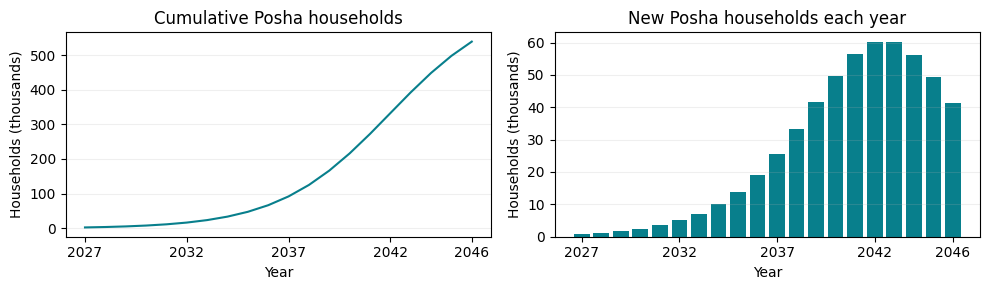

Peak annual adoption: 2042, about 60,137 households


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(forecast.year, forecast.cumulative_adopters / 1000, color='#087f8c')
axes[0].set(title='Cumulative Posha households', ylabel='Households (thousands)', xlabel='Year')
axes[1].bar(forecast.year, forecast.new_adopters / 1000, color='#087f8c')
axes[1].set(title='New Posha households each year', ylabel='Households (thousands)', xlabel='Year')
for ax in axes:
    ax.set_xticks([2027, 2032, 2037, 2042, 2046])
    ax.ticklabel_format(style='plain', axis='x', useOffset=False)
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(ROOT / 'img/posha_forecast.png', dpi=180)
plt.show()
peak = forecast.loc[forecast.new_adopters.idxmax()]
print(f'Peak annual adoption: {int(peak.year)}, about {peak.new_adopters:,.0f} households')

## What I understand from the results
The forecast reaches about 7,300 households by 2030 and 47,100 by 2035. By 2046 it reaches about 539,400, still below the assumed market potential. The largest annual addition is around 2042, at about 60,100 households.

Growth starts slowly because p is small. Later, imitation becomes more important in the model. Eventually fewer households remain in the market and annual adoption falls. This explains the S-shaped cumulative curve and the rise and fall in new adopters. It does not prove that word of mouth caused the historical growth.

The main limits are the ownership proxy, comparing a product category with one brand, and the assumed Posha market shares. The historical curve also levels off below the last ownership observation. Price changes, competition, supply limits and household growth are not included. The forecast assumes Posha continues as a product line over these years. I would use it as a possible scenario and update it when actual customer data becomes available.

# References

[R1] Barker Bonomo, E. (2025, October 9). Posha: Robotic home chef. TIME, Best Inventions of 2025. [TIME entry](https://time.com/collections/best-inventions-2025/7318336/posha/).

[R2] Posha. (n.d.). How Posha works. [Manufacturer page](https://www.posha.com/how-posha-works). Accessed October 19, 2026. Source for product features, U.S. shipping, regular price of $1,750 and the statement that Posha is in 1,000+ homes. Prices and availability can change.

[R3] U.S. Energy Information Administration. (2012). Annual Energy Review 2011, Table 2.6: Household end uses, selected years, 1978-2009. [Historical data](https://www.eia.gov/totalenergy/data/annual/showtext.php?t=ptb0206). Source for microwave ownership and household totals. The original table is saved in data/.

[R4] U.S. Census Bureau. (2025). 2024 American Community Survey, 1-Year Estimates, S1101: Households and families, United States. [Census table](https://data.census.gov/table/ACSST1Y2024.S1101). Total households: 132,737,146.

[R5] Liegey, P. R. (2000). Hedonic quality adjustment methods for microwave ovens in the U.S. CPI. U.S. Bureau of Labor Statistics. [BLS article](https://www.bls.gov/cpi/quality-adjustment/microwave-ovens.htm). Source for the 1967 introduction of the countertop microwave.

[R6] Bass, F. M. (1969). A new product growth for model consumer durables. Management Science, 15(5), 215-227. [Original paper](https://doi.org/10.1287/mnsc.15.5.215).

The 20% eligible share, 2.5% Posha take-up share and exact starting count of 1,000 households are my assumptions. They are not measured market shares or a dated customer total. Sources accessed October 19, 2026.

## Create the PDF
The written report is saved in report/report_source.md. Its tables and discussion use the results shown above. The final cell reads that Markdown and adds the generated charts to create the PDF. All formatting code is in build_report.py.

If I change the analysis, I also need to update the written report before creating the PDF.

In [7]:
from build_report import build_report

pdf_path = build_report()
print('Created report/report.pdf from report/report_source.md.')

Created report/report.pdf from report/report_source.md.
